<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_17_Notebook_36.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **Busca Semântica [LangChain]**
---



In [ ]:
#@title Instalando o pacote LangChain
!pip install langchain

In [ ]:
#@title Versão do LangChain

import langchain

print(langchain.__version__)

1.4.8


In [ ]:
#@title Integração com o pacote da OpenAI

!pip install langchain-openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 588.9/588.9 kB 7.8 MB/s  0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain-openai]


In [ ]:
#@title Definindo a chave da API da OpenAI
from getpass import getpass

OPENAI_API_KEY = getpass()

··········


## **Busca Semântica**

Uma busca semântica de texto é um tipo de pesquisa que entende o significado das palavras e frases — não apenas as palavras exatas digitadas.

👉 Em outras palavras, em vez de procurar apenas correspondências literais de texto (como faz uma busca tradicional por palavras-chave), a busca semântica tenta interpretar a intenção do usuário e o contexto por trás da consulta.

🧠 Como funciona

A busca semântica normalmente usa técnicas de Processamento de Linguagem Natural e modelos de Aprendizado de Máquina (como *`embeddings`* de texto) para representar frases como vetores numéricos em um espaço de significados.

Assim, textos com significados semelhantes ficam “perto” uns dos outros nesse espaço — mesmo que usem palavras diferentes.

### **Primeiro Exemplo**

**Criação da base de documentos**

Será criada uma pequena base de conhecimento sobre diferentes assuntos relacionados a uma universidade.

Cada documento contém um texto e metadados que identificam sua categoria.

In [ ]:
from langchain_core.documents import Document

documentos = [
    Document(
        page_content="A biblioteca universitária oferece livros, periódicos científicos, computadores e espaços de estudo para os alunos.",
        metadata={"categoria": "Biblioteca"}
    ),

    Document(
        page_content="O restaurante universitário oferece refeições a preços acessíveis para estudantes, professores e funcionários.",
        metadata={"categoria": "Alimentação"}
    ),

    Document(
        page_content="O programa de bolsas de iniciação científica incentiva estudantes de graduação a participar de projetos de pesquisa.",
        metadata={"categoria": "Pesquisa"}
    ),

    Document(
        page_content="A universidade oferece atividades esportivas, como futebol, natação e vôlei, para incentivar a prática de exercícios físicos.",
        metadata={"categoria": "Esportes"}
    ),

    Document(
        page_content="Os laboratórios de informática disponibilizam computadores e softwares para atividades práticas e desenvolvimento de projetos.",
        metadata={"categoria": "Informática"}
    ),

    Document(
        page_content="O intercâmbio acadêmico permite que estudantes realizem parte de sua formação em instituições de ensino de outros países.",
        metadata={"categoria": "Internacionalização"}
    )
]

In [ ]:
print(f"Quantidade de documentos: {len(documentos)}")

Quantidade de documentos: 6


**Geração dos *embeddings***

Os *embeddings* representam os textos como vetores numéricos. Dessa maneira, textos com significados semelhantes tendem a apresentar representações vetoriais próximas.

Utilizaremos o modelo `text-embedding-3-small`, da **OpenAI**.

In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings(
    model = "text-embedding-3-small",
    api_key = OPENAI_API_KEY
)

**Criação do banco vetorial**

`InMemoryVectorStore` permite armazenar os documentos e seus respectivos *embeddings* diretamente na memória.

In [ ]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)

vector_store.add_documents(documents = documentos)

['ef348079-181c-4431-8380-31de7a1dd0ab',
 'c5d1b70c-5d12-48f3-abf3-0323ca1e39c3',
 'fbef1149-7fa3-439d-9739-7d5e20a5bca8',
 '913f1cf2-6e38-4542-b610-11cef28b2951',
 'ac8b9d17-f30b-4838-a027-875c44eaf367',
 'cca02235-c464-41c0-bd52-ab6c926c2200']

Nesse momento, os documentos foram convertidos em *embeddings* e armazenados no banco vetorial.

**Realização da busca semântica**

Agora podemos realizar consultas em linguagem natural.

Por exemplo, a pergunta abaixo não utiliza as mesmas palavras do documento sobre a "biblioteca":

In [ ]:
consulta = "Onde posso encontrar materiais para estudar e fazer pesquisas?"

resultados = vector_store.similarity_search( consulta, k=2 )

O parâmetro `k=2` determina que sejam recuperados os dois documentos mais semelhantes à consulta.

**Exibição dos resultados**

Podemos apresentar os documentos recuperados e suas respectivas categorias:



In [ ]:
from IPython.display import display, Markdown

for i, documento in enumerate(resultados, start=1):

    display(Markdown(f"""
### Resultado {i}

**Categoria:** {documento.metadata['categoria']}

**Conteúdo:** {documento.page_content}
"""))


### Resultado 1

**Categoria:** Biblioteca

**Conteúdo:** A biblioteca universitária oferece livros, periódicos científicos, computadores e espaços de estudo para os alunos.



### Resultado 2

**Categoria:** Informática

**Conteúdo:** Os laboratórios de informática disponibilizam computadores e softwares para atividades práticas e desenvolvimento de projetos.


**Testando outras consultas**

Experimente perguntas que utilizam palavras diferentes das encontradas nos documentos:

In [ ]:
consultas = [
    "Quero almoçar dentro da universidade.",
    "Como conseguir participar de um projeto científico?",
    "Onde posso utilizar computadores para desenvolver programas?",
    "Como estudar em uma universidade estrangeira?",
    "Quais atividades posso fazer para cuidar da saúde?"
]

for consulta in consultas:

    resultados = vector_store.similarity_search(
        consulta,
        k=2
    )

    display(Markdown(f"## Consulta: {consulta}"))

    for documento in resultados:

        display(Markdown(
            f"**Categoria:** {documento.metadata['categoria']}  \n"
            f"**Conteúdo:** {documento.page_content}"
        ))

## Consulta: Quero almoçar dentro da universidade.

**Categoria:** Alimentação  
**Conteúdo:** O restaurante universitário oferece refeições a preços acessíveis para estudantes, professores e funcionários.

**Categoria:** Biblioteca  
**Conteúdo:** A biblioteca universitária oferece livros, periódicos científicos, computadores e espaços de estudo para os alunos.

## Consulta: Como conseguir participar de um projeto científico?

**Categoria:** Pesquisa  
**Conteúdo:** O programa de bolsas de iniciação científica incentiva estudantes de graduação a participar de projetos de pesquisa.

**Categoria:** Informática  
**Conteúdo:** Os laboratórios de informática disponibilizam computadores e softwares para atividades práticas e desenvolvimento de projetos.

... (5 outputs left out)

**Categoria:** Biblioteca  
**Conteúdo:** A biblioteca universitária oferece livros, periódicos científicos, computadores e espaços de estudo para os alunos.

## Consulta: Quais atividades posso fazer para cuidar da saúde?

**Categoria:** Esportes  
**Conteúdo:** A universidade oferece atividades esportivas, como futebol, natação e vôlei, para incentivar a prática de exercícios físicos.

**Categoria:** Biblioteca  
**Conteúdo:** A biblioteca universitária oferece livros, periódicos científicos, computadores e espaços de estudo para os alunos.

**Transformando o banco vetorial em um `Retriever`**

O **LangChain** também permite transformar o banco vetorial em um objeto `Retriever`. Isso facilita sua integração com outras funcionalidades do framework, especialmente aplicações RAG.

In [ ]:
retriever = vector_store.as_retriever(
    search_kwargs={"k": 2}
)

resultados = retriever.invoke(
    "Quero desenvolver um trabalho de pesquisa na universidade."
)

for documento in resultados:
    print(documento.page_content)
    print("Categoria:", documento.metadata["categoria"])
    print("-" * 60)

O programa de bolsas de iniciação científica incentiva estudantes de graduação a participar de projetos de pesquisa.
Categoria: Pesquisa
------------------------------------------------------------
Os laboratórios de informática disponibilizam computadores e softwares para atividades práticas e desenvolvimento de projetos.
Categoria: Informática
------------------------------------------------------------


**Entendendo o funcionamento**

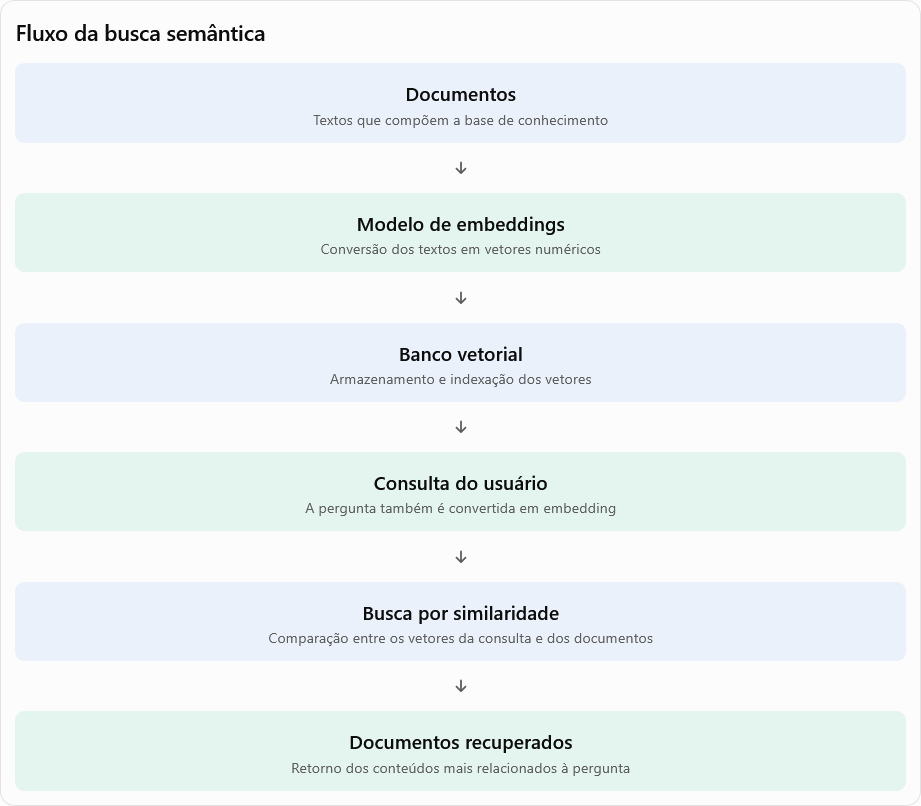

Observações didáticas:

- A busca semântica não exige que a consulta contenha exatamente as palavras dos documentos.
- Os *embeddings* são responsáveis por representar semanticamente os textos.
- O banco vetorial permite recuperar os documentos mais semelhantes à consulta.
- O parâmetro k controla a quantidade de documentos retornados.
- A busca semântica, por si só, não gera respostas: ela recupera documentos. A geração de respostas com um modelo de linguagem é uma etapa adicional, utilizada em aplicações RAG.


[Referência: LangChain – Build a semantic search engine with LangChain](https://docs.langchain.com/oss/python/langchain/knowledge-base?utm_source=chatgpt.com)

### **Página Web**

A ideia é utilizar uma página HTML como fonte de dados. O **LangChain** fará a leitura do conteúdo, dividirá o texto em documentos menores, criará os *embeddings* e permitirá pesquisar informações utilizando um `Retriever`.

**Carregamento da página Web**

Utilizaremos as bibliotecas `requests` e `BeautifulSoup` para acessar uma página Web, extrair seu conteúdo textual e, posteriormente, convertê-lo em um objeto `Document` do **LangChain**, que permite armazenar o texto e seus respectivos metadados para utilização nas etapas seguintes de processamento e busca semântica.

In [ ]:
import requests
from bs4 import BeautifulSoup
from langchain_core.documents import Document

url = "https://docs.python.org/3/tutorial/introduction.html"

# Requisição HTTP
resposta = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0 (compatible; LangChainExample/1.0)"},
    timeout=30
)

resposta.raise_for_status()

# Extração do conteúdo HTML
soup = BeautifulSoup(resposta.text, "html.parser")

# Remoção de elementos desnecessários
for elemento in soup(["script", "style", "nav", "footer"]):
    elemento.decompose()

# Extração do texto
conteudo = soup.get_text(separator="\n", strip=True)

# Criação do documento LangChain
documentos = [
    Document(
        page_content=conteudo,
        metadata={
            "source": url,
            "title": soup.title.get_text(strip=True) if soup.title else ""
        }
    )
]

In [ ]:
print("Quantidade de documentos:", len(documentos))
print("Quantidade de caracteres:", len(documentos[0].page_content))

Quantidade de documentos: 1
Quantidade de caracteres: 18362


In [ ]:
print(documentos[0].page_content[:50])

3. An Informal Introduction to Python — Python 3.1


**Divisão do conteúdo em partes menores**

Uma página pode conter milhares de caracteres. Por isso, é interessante dividir seu conteúdo em trechos menores (*chunks*).

Isso facilita a recuperação de informações específicas durante a busca semântica.

In [ ]:
!pip install -qU langchain-text-splitters

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

divisor = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=100
)

documentos_divididos = divisor.split_documents(documentos)

print("Quantidade de partes:", len(documentos_divididos))

Quantidade de partes: 46


Os parâmetros utilizados são:
- `chunk_size=500`: tamanho máximo aproximado de cada trecho, em caracteres.
- `chunk_overlap=100`: quantidade de caracteres compartilhados entre trechos consecutivos.

Podemos visualizar um dos trechos:

In [ ]:
print(documentos_divididos[0].page_content)

3. An Informal Introduction to Python — Python 3.15.2 documentation
Navigation
index
modules
|
next
|
previous
|
Python
»
3.15.2 documentation
»
The Python Tutorial
»
3.
An Informal Introduction to Python
|
Theme
Auto
Light
Dark
|
3.
An Informal Introduction to Python
Â¶
In the following examples, input and output are distinguished by the presence or
absence of prompts (
>>>
and
â¦
): to repeat the example, you must type


**Geração dos *embeddings***



Agora, utilizaremos o modelo de *embeddings* da **OpenAI** para transformar os trechos em representações vetoriais.

In [ ]:
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings( model="text-embedding-3-small", api_key=OPENAI_API_KEY )

**Criação do banco vetorial**

Armazenaremos os documentos e seus *embeddings* utilizando `InMemoryVectorStore`.

In [ ]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)

vector_store.add_documents( documents=documentos_divididos )

['4810116a-1b20-4524-aa27-85e7a49a6763',
 'b4f522d4-7760-4197-b5d6-e1ca58ff05a0',
 'fb550db6-c685-454c-89f2-6a0287b08c36',
 'a65e0014-fa1e-497c-aa55-a8202a7f93ba',
 '4af9f824-e15d-410d-ac6a-a0f66ff60409',
 '9b9ccc8d-1aeb-46d6-8113-e6cffa6ffa8e',
 '9af1628d-096d-4f3e-9c44-e2746acc043f',
 '3b486e10-bc3c-4977-8094-c599201a568b',
 'd09d6f91-5cc5-4e6a-a8cd-6b2fb1f539df',
 '47144664-c583-4483-9877-185722f55a38',
 '22fbc3f3-22c3-4750-9aee-30da2154f9f7',
 '95dc1ac4-761b-4048-bd19-af020740df7f',
 'd48f08c0-fd87-429a-b862-18520973261e',
 'e9ac38ab-b324-4ad4-bf87-7899b11277b1',
 '51fc5da3-31fb-4ff5-aa2f-f3a205944536',
 '3af4a336-01c6-4898-86f6-10b4c50d5583',
 '440eb7aa-c850-4fd6-b8b8-7db1359f0ead',
 '788002a2-e9cc-47e4-b9cb-c2bb48c7e38b',
 '67d6f42c-0413-46b5-832a-f42c3cb7fd98',
 'aacaa7e9-7ca4-4b0f-8c8a-940f76091572',
 'daf47b7d-48eb-4058-893f-45222d627fe0',
 '161a47e0-30bc-4499-a201-09fcb276b7ac',
 '966b215f-73eb-440e-8409-169fcd3550fd',
 '58767a81-a019-4cf0-84d4-c4c9cb625f49',
 'bf84bca6-3706-

A partir desse momento, temos uma representação vetorial do conteúdo da página Web, que poderá ser consultada semanticamente.

**Criação do `Retriever`**

Transformamos o banco vetorial em um `Retriever`, definindo que serão recuperados os três trechos mais relevantes para cada consulta.

In [ ]:
retriever = vector_store.as_retriever( search_kwargs={"k": 2} )

**Realização da busca semântica**

Agora podemos fazer perguntas sobre o conteúdo da página, mesmo sem utilizar exatamente as palavras presentes no texto original.

In [ ]:
consulta = "Como realizar operações matemáticas?"

resultados = retriever.invoke(consulta)

In [ ]:
from IPython.display import display, Markdown

display(Markdown(f"# Consulta: {consulta}"))

for i, documento in enumerate(resultados, start=1):

    display(Markdown(f"""
### Resultado {i}

{documento.page_content}

---
"""))

# Consulta: Como realizar operações matemáticas?


### Resultado 1

operators
+
,
-
,
*
and
/
can be used to perform
arithmetic; parentheses (
()
) can be used for grouping.
For example:
>>>
2
+
2
4
>>>
50
-
5
*
6
20
>>>
(
50
-
5
*
6
)
/
4
5.0
>>>
8
/
5
# division always returns a floating-point number
1.6
The integer numbers (e.g.
2
,
4
,
20
) have type
int
,
the ones with a fractional part (e.g.
5.0
,
1.6
) have type
float
.  We will see more about numeric types later in the tutorial.
Division (
/
) always returns a float.  To do
floor division
and

---



### Resultado 2

text
=
"# This is not a comment because it's inside quotes."
3.1.
Using Python as a Calculator
Â¶
Letâs try some simple Python commands.  Start the interpreter and wait for the
primary prompt,
>>>
.  (It shouldnât take long.)
3.1.1.
Numbers
Â¶
The interpreter acts as a simple calculator: you can type an expression into it
and it will write the value.  Expression syntax is straightforward: the
operators
+
,
-
,
*
and
/
can be used to perform
arithmetic; parentheses (
()

---


### **RAG**

Uma boa continuação didática seria utilizar essa mesma base de documentos para construir uma aplicação RAG, conectando o `Retriever` a um modelo de linguagem da OpenAI.

**Para fins didáticos**: no seu exemplo com LangChain, as perguntas em inglês são consultas de busca semântica. O `Retriever` retorna os trechos mais relevantes da documentação Python, mas não formula respostas.

O próximo passo natural seria transformar esse exemplo em uma aplicação RAG, permitindo que o aluno faça perguntas sobre a documentação Python e receba respostas elaboradas pelo modelo da OpenAI, utilizando exclusivamente os trechos recuperados como contexto

**Criação do prompt para RAG**

Utilizaremos `ChatPromptTemplate` para construir um prompt que receberá duas informações:

- `{context}`: trechos da documentação recuperados pelo Retriever.
- `{question}`: pergunta realizada pelo usuário.

O prompt orientará o modelo a responder utilizando exclusivamente o contexto fornecido. Caso não encontre informações suficientes, deverá informar essa limitação.

In [ ]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template("""
Você é um assistente especializado em Python.

Responda à pergunta utilizando exclusivamente as informações
presentes no contexto fornecido.

Se o contexto não apresentar informações suficientes,
informe que não foi possível encontrar a resposta na documentação.

Contexto:
{context}

Pergunta:
{question}

Resposta:
""")

**Configuração do modelo de linguagem**

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI( model="gpt-6-luna", api_key=OPENAI_API_KEY )

**Construção da aplicação RAG**

Primeiro, recuperamos os documentos relevantes. Depois, reunimos seus conteúdos em um único contexto e enviamos esse contexto junto com a pergunta ao modelo.

In [ ]:
from langchain_core.output_parsers import StrOutputParser

pergunta = "Como posso criar e usar variáveis ​​em Python??"

# Recuperação dos documentos relevantes
documentos_recuperados = retriever.invoke(pergunta)

# Organização do contexto
contexto = "\n\n".join(
    documento.page_content
    for documento in documentos_recuperados
)

# Construção da cadeia RAG
rag_chain = prompt | modelo | StrOutputParser()

# Geração da resposta
resposta = rag_chain.invoke({
    "context": contexto,
    "question": pergunta
})

**Exibição da resposta em Markdown**

In [ ]:
from IPython.display import display, Markdown

display(Markdown(f"""
# Pergunta

{pergunta}

---

# Resposta

{resposta}
"""))


# Pergunta

Como posso criar e usar variáveis ​​em Python??

---

# Resposta

Use o sinal de igual (`=`) para atribuir um valor a uma variável. Por exemplo:

```python
width = 20
height = 5 * 9
area = width * height
```

Depois de atribuir um valor, você pode usar a variável em cálculos. A atribuição não exibe um resultado no prompt interativo; o resultado aparece quando você avalia uma expressão, como `area`.

Se tentar usar uma variável antes de atribuir um valor a ela, ocorrerá um erro.
